In [ ]:
# Install tensorflow if missing
!pip install tensorflow

# ---- All imports ----
import os, io, glob, json, shutil, random, zipfile, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import drive, files
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore", message="Palette images with Transparency")

# Check how many GPUs are available
print("Num GPUs Available: ", len(tf.config.experimental.list_physical_devices('GPU')))

Num GPUs Available:  1


In [ ]:
drive.mount('/content/drive')

CONFIG = {
    "fer":    dict(zip="/content/drive/MyDrive/Data/faces.zip",   img=(48, 48), epochs=40),
    "mask":   dict(zip="/content/drive/MyDrive/Data/masks.zip",   img=(64, 64), epochs=15),
    "fruits": dict(zip="/content/drive/MyDrive/Data/fruits.zip",  img=(64, 64), epochs=15),
}
FRUITS = ["Apple", "Banana", "Avocado", "Tomato", "Eggplant"]
BATCH_SIZE, SEED = 32, 42
OUT_DIR = "/content/drive/MyDrive/Data/models"
os.makedirs(OUT_DIR, exist_ok=True)

def find_dir(root, *names):
    for d, subs, _ in os.walk(root):
        for s in subs:
            if s.lower() in names:
                return os.path.join(d, s)
    return None

def group_fruits(src, dst):
    # merge varieties ("Apple Braeburn 1", ...) into one class per fruit
    # random prefix shuffles file order, so validation_split gets a mix of varieties
    random.seed(SEED)
    for cls in os.listdir(src):
        key = next((f for f in FRUITS if cls.split()[0].lower() == f.lower()), None)
        if not key:
            continue
        out = os.path.join(dst, key)
        os.makedirs(out, exist_ok=True)
        for f in glob.glob(os.path.join(src, cls, "*")):
            new = f"{random.random():.8f}_{cls.replace(' ', '_')}_{os.path.basename(f)}"
            shutil.copy(f, os.path.join(out, new))

def descend(root):
    # step into wrapper folders (e.g. FMD_DATASET/) until real content appears
    while True:
        items = [i for i in os.listdir(root) if i != "__MACOSX"]
        subs = [i for i in items if os.path.isdir(os.path.join(root, i))]
        if len(subs) == 1 and len(subs) == len(items):
            root = os.path.join(root, subs[0])
        else:
            return root

Mounted at /content/drive


In [ ]:
def build_model(img, n):
    m = models.Sequential([
        layers.Input(shape=(img[0], img[1], 3)),
        layers.Conv2D(32, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(n, activation='softmax'),
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def run(name):
    cfg = CONFIG[name]
    IMG = cfg["img"]

    # Always extract freshly to avoid corrupted or missing files
    ddir = f"/content/dataset_{name}"
    if os.path.exists(ddir):
        shutil.rmtree(ddir)

    print(f"Extracting {name} dataset...")
    with zipfile.ZipFile(cfg["zip"]) as z:
        z.extractall(ddir)

    # Locate root folders
    train_dir = find_dir(ddir, "train", "training") or descend(ddir)
    test_dir = find_dir(ddir, "test") or find_dir(ddir, "validation", "val")

    if name == "fruits":
        shutil.rmtree("/content/fruits5", ignore_errors=True)
        group_fruits(train_dir, "/content/fruits5/train")
        train_dir = "/content/fruits5/train"
        if test_dir:
            group_fruits(test_dir, "/content/fruits5/test")
            test_dir = "/content/fruits5/test"

    if name == "mask":
        random.seed(SEED)
        shutil.rmtree("/content/mask2", ignore_errors=True)
        for c in ["with_mask", "without_mask"]:
            os.makedirs(f"/content/mask2/{c}", exist_ok=True)

            # find the class folder anywhere under train_dir
            src_class_dir = None
            for r, dirs, _ in os.walk(train_dir):
                for d in dirs:
                    if d.lower() == c.lower():
                        src_class_dir = os.path.join(r, d)
                        break
                if src_class_dir:
                    break
            if src_class_dir is None:
                src_class_dir = os.path.join(train_dir, c)

            # collect images at any depth; random prefix shuffles the split
            all_files = []
            for root_dir, _, fs in os.walk(src_class_dir):
                for file in fs:
                    if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp", ".bmp")):
                        all_files.append(os.path.join(root_dir, file))

            print(f"Found {len(all_files)} images for class {c} inside {src_class_dir}")
            for f in all_files:
                shutil.copy(f, f"/content/mask2/{c}/{random.random():.8f}_{os.path.basename(f)}")
        train_dir = "/content/mask2"

    print(name, "| train:", train_dir, "| test:", test_dir)

    # Generators
    aug = ImageDataGenerator(rescale=1/255, rotation_range=10, zoom_range=0.15,
                             width_shift_range=0.1, height_shift_range=0.1,
                             horizontal_flip=True, validation_split=0.2)
    plain = ImageDataGenerator(rescale=1/255, validation_split=0.2)
    kw = dict(target_size=IMG, batch_size=BATCH_SIZE, class_mode="categorical", seed=SEED)

    train_set = aug.flow_from_directory(train_dir, subset="training", shuffle=True, **kw)
    val_set = plain.flow_from_directory(train_dir, subset="validation", shuffle=False, **kw)
    test_set = (ImageDataGenerator(rescale=1/255).flow_from_directory(test_dir, shuffle=False, **kw)
                if test_dir else val_set)

    class_names = [n for n, i in sorted(train_set.class_indices.items(), key=lambda x: x[1])]
    assert len(class_names) > 1, f"Only {class_names} found - check folder layout"
    print("Classes:", class_names)

    # Class weights for imbalanced datasets (fruits, fer)
    cw = None
    if name in ("fruits", "fer"):
        w = compute_class_weight("balanced", classes=np.unique(train_set.classes), y=train_set.classes)
        cw = dict(enumerate(w))

    # Model initialization and training
    cnn = build_model(IMG, len(class_names))
    cbs = [EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
           ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)]
    hist = cnn.fit(train_set, validation_data=val_set, epochs=cfg["epochs"],
                   callbacks=cbs, verbose=2, class_weight=cw)
    json.dump(hist.history, open(f"{OUT_DIR}/{name}_history.json", "w"))

    # Evaluation
    test_set.reset()
    loss, acc = cnn.evaluate(test_set, verbose=0)
    test_set.reset()
    y_pred = np.argmax(cnn.predict(test_set, verbose=0), axis=1)
    print(f"\n{name} test accuracy: {acc:.2%}")
    print(classification_report(test_set.classes, y_pred, target_names=class_names, zero_division=0))

    # Visualizations (also saved to Drive)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist.history['accuracy'], label='Training accuracy')
    plt.plot(hist.history['val_accuracy'], label='Validation accuracy')
    plt.title(f'{name} - Accuracy'); plt.xlabel('Epoch'); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(hist.history['loss'], label='Training loss')
    plt.plot(hist.history['val_loss'], label='Validation loss')
    plt.title(f'{name} - Loss'); plt.xlabel('Epoch'); plt.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{name}_curves.png", dpi=150)
    plt.show()

    cm = confusion_matrix(test_set.classes, y_pred, labels=range(len(class_names)))
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'{name} - Confusion Matrix')
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{name}_confusion_matrix.png", dpi=150)
    plt.show()

    cnn.save(f"{OUT_DIR}/{name}_model.keras")
    json.dump(class_names, open(f"{OUT_DIR}/{name}_class_names.json", "w"))
    print(f"Saved to {OUT_DIR}/{name}_model.keras")
    return cnn, hist, acc

In [ ]:
def evaluate_saved(name):
    model = tf.keras.models.load_model(f"{OUT_DIR}/{name}_model.keras")
    class_names = json.load(open(f"{OUT_DIR}/{name}_class_names.json"))
    h, w = model.input_shape[1:3]

    ddir = f"/content/dataset_{name}"
    train_dir = find_dir(ddir, "train", "training") or descend(ddir)
    test_dir = find_dir(ddir, "test") or find_dir(ddir, "validation", "val")
    if name == "mask":
        train_dir, test_dir = "/content/mask2", None
    if name == "fruits":
        train_dir = "/content/fruits5/train"
        test_dir = "/content/fruits5/test" if os.path.exists("/content/fruits5/test") else None

    kw = dict(target_size=(h, w), batch_size=BATCH_SIZE, class_mode="categorical",
              seed=SEED, shuffle=False)
    if test_dir:
        ev = ImageDataGenerator(rescale=1/255).flow_from_directory(test_dir, **kw)
    else:
        ev = ImageDataGenerator(rescale=1/255, validation_split=0.2).flow_from_directory(
            train_dir, subset="validation", **kw)

    loss, acc = model.evaluate(ev, verbose=0)
    y_pred = np.argmax(model.predict(ev, verbose=0), axis=1)
    print(f"{name} accuracy: {acc:.2%}")
    print(classification_report(ev.classes, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(ev.classes, y_pred, labels=range(len(class_names)))
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'{name} - Confusion Matrix')
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{name}_confusion_matrix.png", dpi=150)
    plt.show()

def show_results(name):
    h = json.load(open(f"{OUT_DIR}/{name}_history.json"))
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(h['accuracy'], label='Training accuracy')
    plt.plot(h['val_accuracy'], label='Validation accuracy')
    plt.title(f'{name} - Accuracy'); plt.xlabel('Epoch'); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(h['loss'], label='Training loss')
    plt.plot(h['val_loss'], label='Validation loss')
    plt.title(f'{name} - Loss'); plt.xlabel('Epoch'); plt.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{name}_curves.png", dpi=150)
    plt.show()
    evaluate_saved(name)   # report + confusion matrix

 MASK 
Extracting mask dataset...
Found 4789 images for class with_mask inside /content/dataset_mask/FMD_DATASET/with_mask
Found 4747 images for class without_mask inside /content/dataset_mask/FMD_DATASET/without_mask
mask | train: /content/mask2 | test: None
Found 7630 images belonging to 2 classes.
Found 1906 images belonging to 2 classes.
Classes: ['with_mask', 'without_mask']
Epoch 1/15
239/239 - 61s - 255ms/step - accuracy: 0.8615 - loss: 0.3230 - val_accuracy: 0.4979 - val_loss: 2.3647 - learning_rate: 0.0010
Epoch 2/15
239/239 - 39s - 164ms/step - accuracy: 0.9073 - loss: 0.2155 - val_accuracy: 0.7775 - val_loss: 0.5514 - learning_rate: 0.0010
Epoch 3/15
239/239 - 40s - 167ms/step - accuracy: 0.9216 - loss: 0.1813 - val_accuracy: 0.8641 - val_loss: 0.3652 - learning_rate: 0.0010
Epoch 4/15
239/239 - 41s - 172ms/step - accuracy: 0.9290 - loss: 0.1657 - val_accuracy: 0.9224 - val_loss: 0.2066 - learning_rate: 0.0010
Epoch 5/15
239/239 - 41s - 172ms/step - accuracy: 0.9360 - loss: 

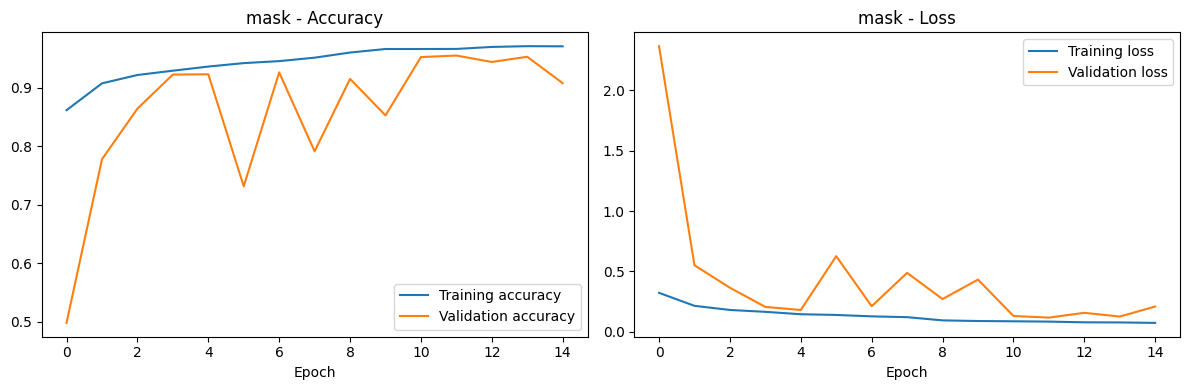

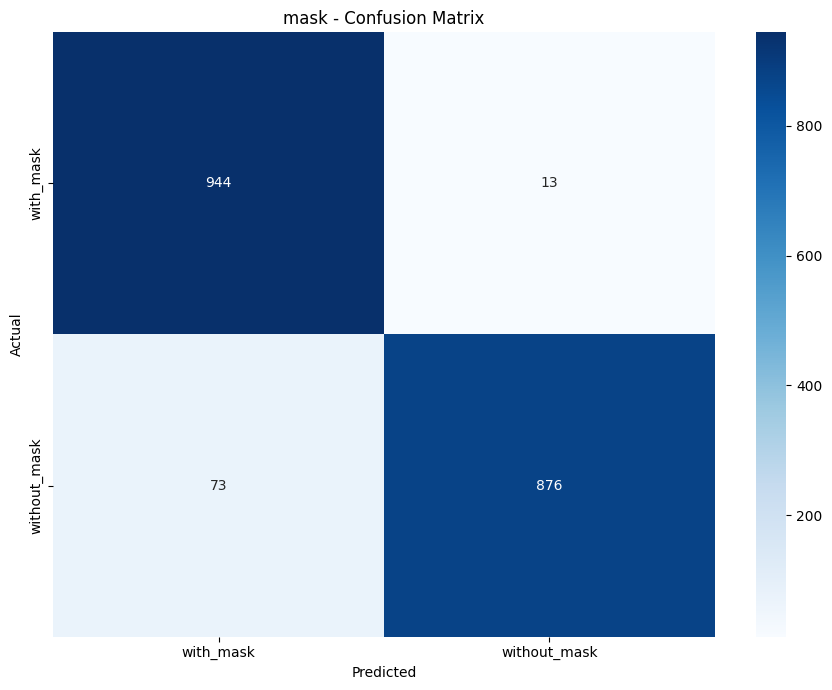

Saved to /content/drive/MyDrive/Data/models/mask_model.keras
 FRUITS 
Extracting fruits dataset...
fruits | train: /content/fruits5/train | test: /content/fruits5/test
Found 26014 images belonging to 5 classes.
Found 6501 images belonging to 5 classes.
Found 10817 images belonging to 5 classes.
Classes: ['Apple', 'Avocado', 'Banana', 'Eggplant', 'Tomato']
Epoch 1/15
813/813 - 63s - 77ms/step - accuracy: 0.8786 - loss: 0.2722 - val_accuracy: 0.8119 - val_loss: 0.5252 - learning_rate: 0.0010
Epoch 2/15
813/813 - 45s - 55ms/step - accuracy: 0.9618 - loss: 0.0768 - val_accuracy: 0.9099 - val_loss: 0.3415 - learning_rate: 0.0010
Epoch 3/15
813/813 - 45s - 55ms/step - accuracy: 0.9694 - loss: 0.0646 - val_accuracy: 0.7393 - val_loss: 2.7098 - learning_rate: 0.0010
Epoch 4/15
813/813 - 45s - 55ms/step - accuracy: 0.9843 - loss: 0.0311 - val_accuracy: 0.8836 - val_loss: 0.6413 - learning_rate: 0.0010
Epoch 5/15
813/813 - 45s - 55ms/step - accuracy: 0.9863 - loss: 0.0305 - val_accuracy: 0.7691 

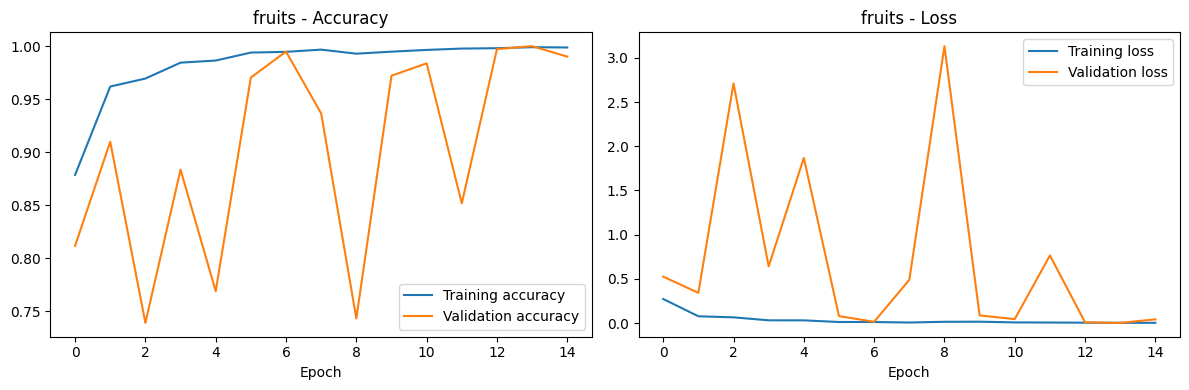

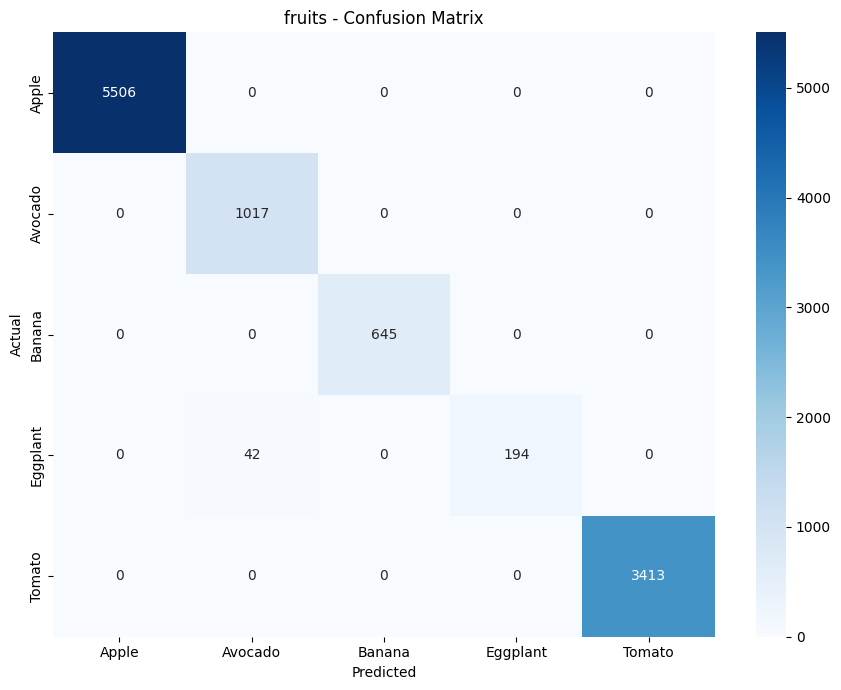

Saved to /content/drive/MyDrive/Data/models/fruits_model.keras
 FER 
Extracting fer dataset...
fer | train: /content/dataset_fer/train | test: /content/dataset_fer/test
Found 22968 images belonging to 7 classes.
Found 5741 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Epoch 1/40
718/718 - 49s - 68ms/step - accuracy: 0.1810 - loss: 1.9405 - val_accuracy: 0.1968 - val_loss: 1.9054 - learning_rate: 0.0010
Epoch 2/40
718/718 - 28s - 39ms/step - accuracy: 0.2250 - loss: 1.8534 - val_accuracy: 0.2238 - val_loss: 1.8603 - learning_rate: 0.0010
Epoch 3/40
718/718 - 28s - 38ms/step - accuracy: 0.2571 - loss: 1.7738 - val_accuracy: 0.2113 - val_loss: 1.8477 - learning_rate: 0.0010
Epoch 4/40
718/718 - 27s - 38ms/step - accuracy: 0.3088 - loss: 1.7186 - val_accuracy: 0.2425 - val_loss: 1.8098 - learning_rate: 0.0010
Epoch 5/40
718/718 - 27s - 38ms/step - accuracy: 0.3425 - loss: 1.6427 - val_ac

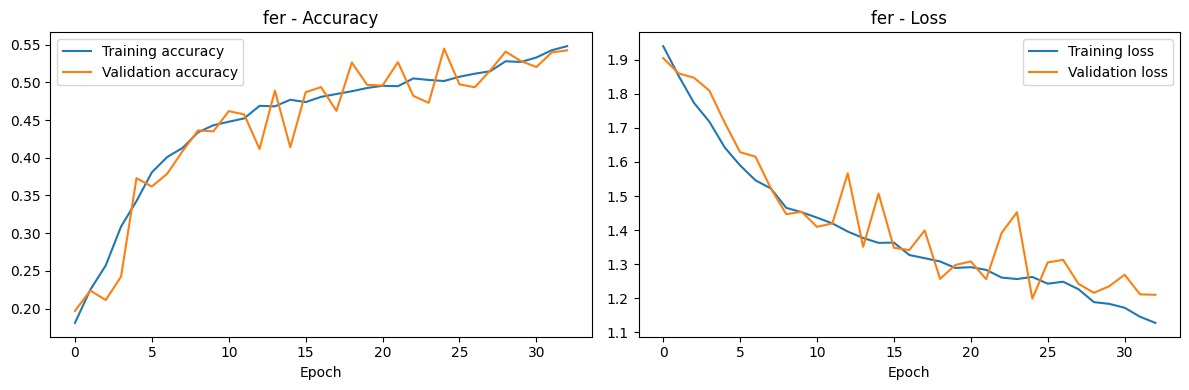

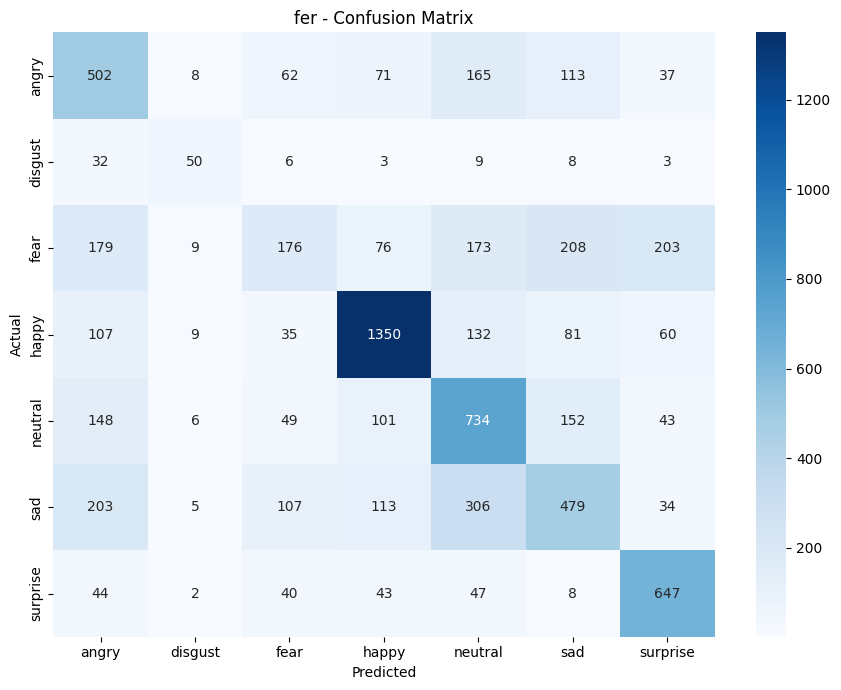

Saved to /content/drive/MyDrive/Data/models/fer_model.keras
{'mask': '95.49%', 'fruits': '99.61%', 'fer': '54.86%'}


In [ ]:
results = {}
for name in ["mask", "fruits", "fer"]:   # remove a name here to skip a finished dataset
    print("=" * 60, "\n", name.upper(), "\n", "=" * 60)
    cnn, hist, acc = run(name)
    results[name] = acc
    tf.keras.backend.clear_session()

print({k: f"{v:.2%}" for k, v in results.items()})

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = router.fit(
    r_train,
    validation_data=r_val,
    epochs=30,
    callbacks=callbacks,
    verbose=2
)

print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

with open(f"{OUT_DIR}/router_history.json", "w") as f:
    json.dump(history.history, f)

router_names = [
    name for name, index in sorted(
        r_train.class_indices.items(),
        key=lambda item: item[1]
    )
]

router.save(f"{OUT_DIR}/router_model.keras")

with open(f"{OUT_DIR}/router_class_names.json", "w") as f:
    json.dump(router_names, f)

print("Router classes:", router_names)
print("Router saved successfully.")

Epoch 1/30
150/150 - 8s - 51ms/step - accuracy: 0.9950 - loss: 0.0148 - val_accuracy: 0.7542 - val_loss: 1.6108 - learning_rate: 0.0010
Epoch 2/30
150/150 - 8s - 51ms/step - accuracy: 0.9981 - loss: 0.0071 - val_accuracy: 0.9392 - val_loss: 0.1409 - learning_rate: 0.0010
Epoch 3/30
150/150 - 8s - 50ms/step - accuracy: 0.9969 - loss: 0.0098 - val_accuracy: 0.9450 - val_loss: 0.1309 - learning_rate: 0.0010
Epoch 4/30
150/150 - 8s - 51ms/step - accuracy: 0.9967 - loss: 0.0106 - val_accuracy: 0.9917 - val_loss: 0.0229 - learning_rate: 0.0010
Epoch 5/30
150/150 - 8s - 51ms/step - accuracy: 0.9958 - loss: 0.0132 - val_accuracy: 0.7383 - val_loss: 1.9446 - learning_rate: 0.0010
Epoch 6/30
150/150 - 8s - 50ms/step - accuracy: 0.9958 - loss: 0.0106 - val_accuracy: 0.9942 - val_loss: 0.0248 - learning_rate: 0.0010
Epoch 7/30
150/150 - 8s - 50ms/step - accuracy: 0.9979 - loss: 0.0058 - val_accuracy: 0.9958 - val_loss: 0.0109 - learning_rate: 5.0000e-04
Epoch 8/30
150/150 - 8s - 51ms/step - accura

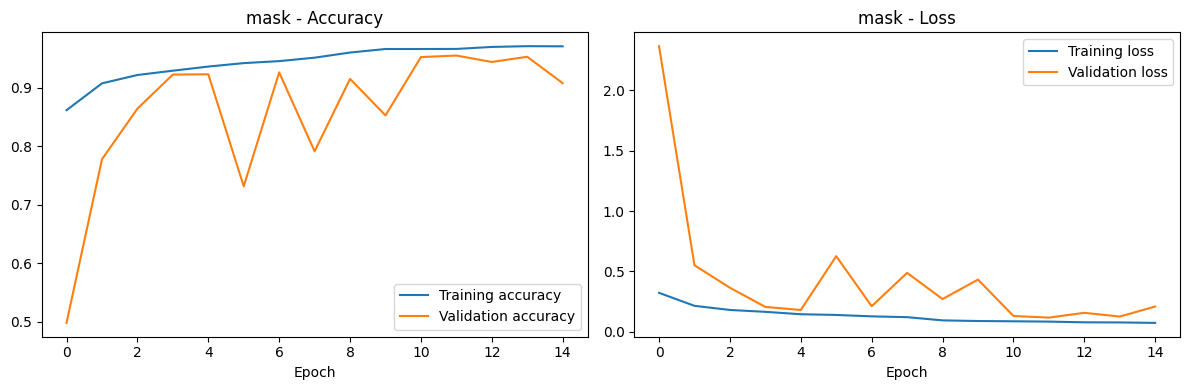

Found 1906 images belonging to 2 classes.
mask accuracy: 95.49%
              precision    recall  f1-score   support

   with_mask       0.93      0.99      0.96       957
without_mask       0.99      0.92      0.95       949

    accuracy                           0.95      1906
   macro avg       0.96      0.95      0.95      1906
weighted avg       0.96      0.95      0.95      1906



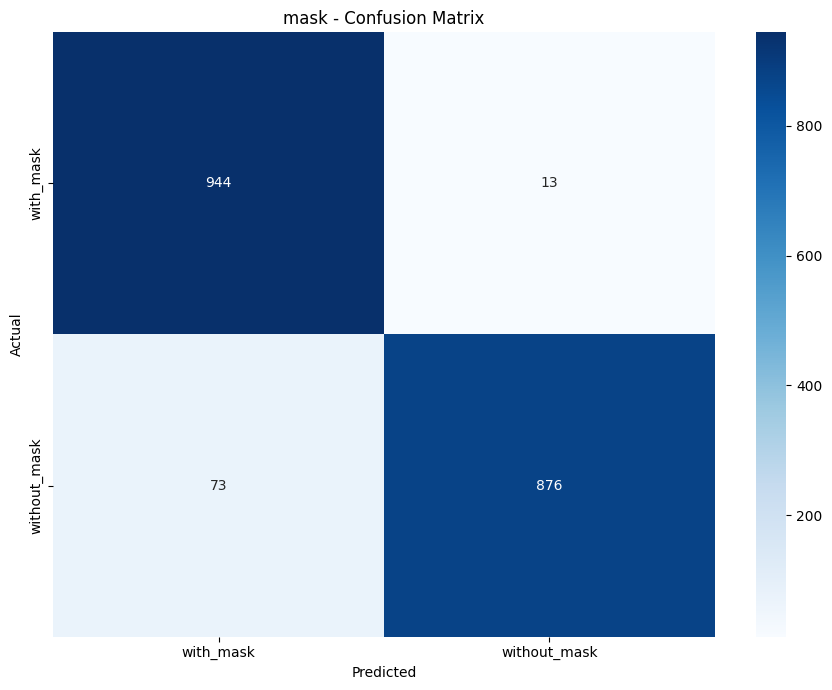

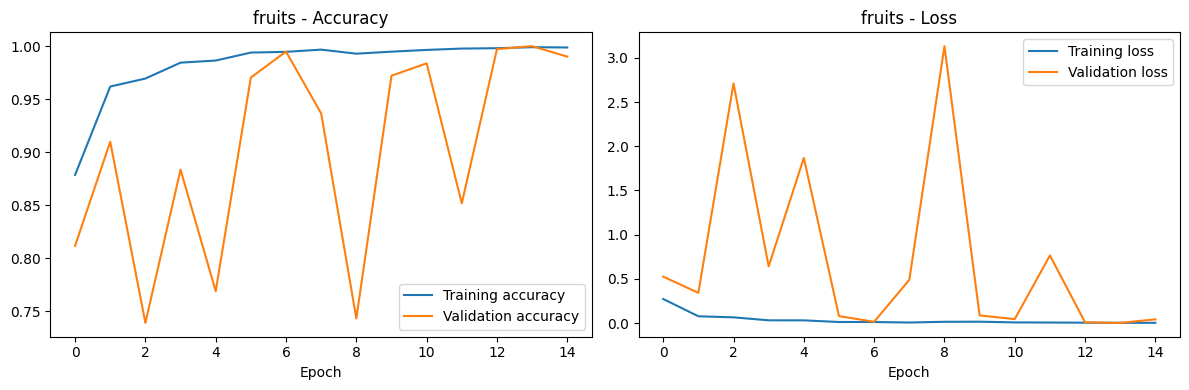

Found 10817 images belonging to 5 classes.
fruits accuracy: 99.61%
              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00      5506
     Avocado       0.96      1.00      0.98      1017
      Banana       1.00      1.00      1.00       645
    Eggplant       1.00      0.82      0.90       236
      Tomato       1.00      1.00      1.00      3413

    accuracy                           1.00     10817
   macro avg       0.99      0.96      0.98     10817
weighted avg       1.00      1.00      1.00     10817



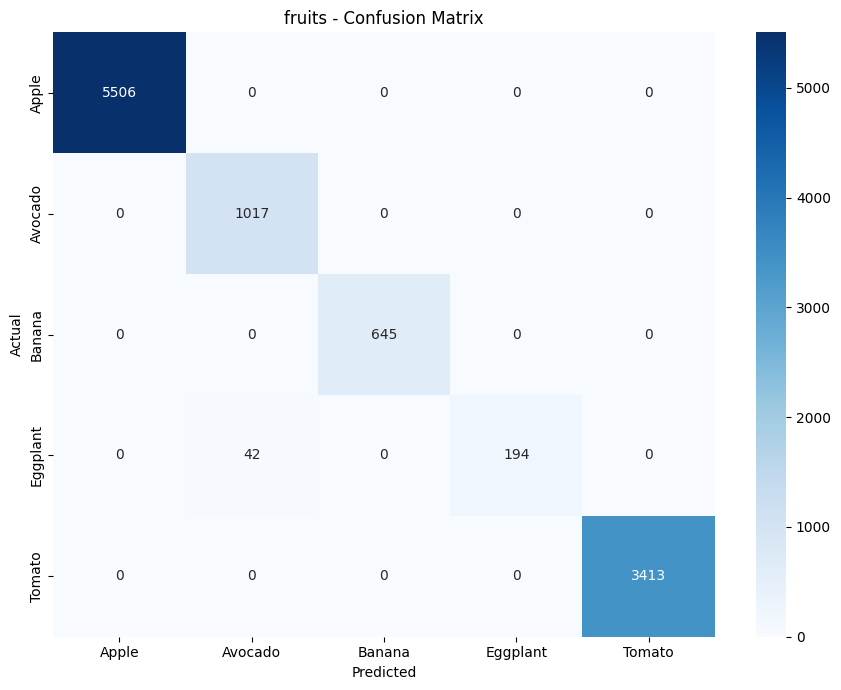

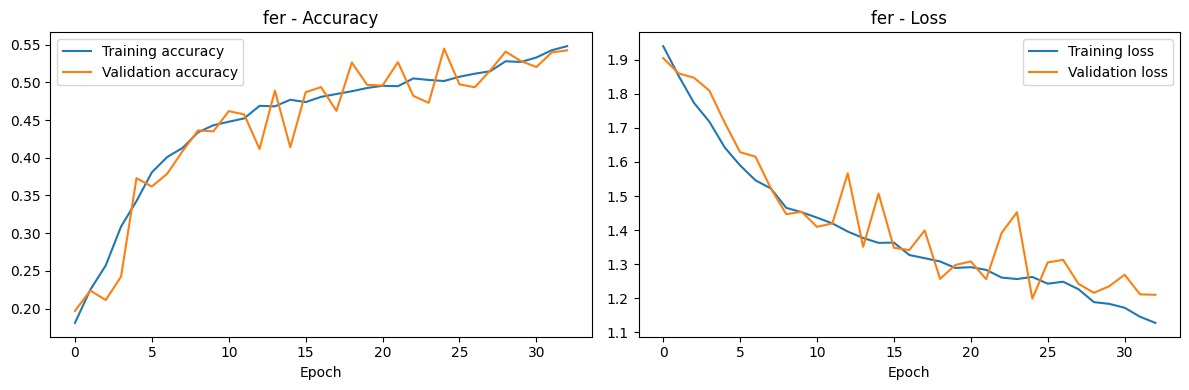

Found 7178 images belonging to 7 classes.
fer accuracy: 54.86%
              precision    recall  f1-score   support

       angry       0.41      0.52      0.46       958
     disgust       0.56      0.45      0.50       111
        fear       0.37      0.17      0.23      1024
       happy       0.77      0.76      0.76      1774
     neutral       0.47      0.60      0.52      1233
         sad       0.46      0.38      0.42      1247
    surprise       0.63      0.78      0.70       831

    accuracy                           0.55      7178
   macro avg       0.52      0.52      0.51      7178
weighted avg       0.54      0.55      0.54      7178



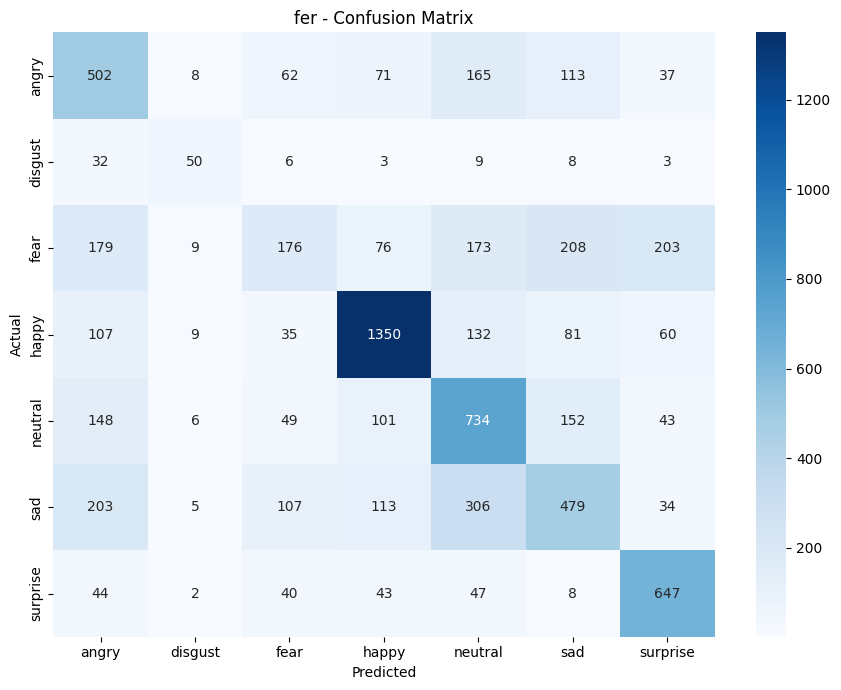

In [ ]:
for n in ["mask", "fruits", "fer"]:
    show_results(n)   # curves + report + confusion matrix (all saved to Drive as PNG)